<a href="https://colab.research.google.com/github/Widpepo/steam-data-science/blob/main/notebook/analise_steam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**1. Obtenção dos dados**

 o Google Drive acessa o dataset e é carregado utilizando a biblioteca Pandas, permitindo visualizar sua estrutura, quantidade de registros e variáveis disponíveis.

In [31]:

from google.colab import drive

drive.mount('/content/drive')



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [32]:

import pandas as pd

path = '/content/drive/MyDrive/Dataset/games_march2025_full.csv'

df = pd.read_csv(path)

# Dimensões do dataset
print("Linhas e colunas:", df.shape)

# Nomes das colunas
print("\nColunas disponíveis:")
print(df.columns.tolist())

display(df.head())

df.info()


Linhas e colunas: (94948, 47)

Colunas disponíveis:
['appid', 'name', 'release_date', 'required_age', 'price', 'dlc_count', 'detailed_description', 'about_the_game', 'short_description', 'reviews', 'header_image', 'website', 'support_url', 'support_email', 'windows', 'mac', 'linux', 'metacritic_score', 'metacritic_url', 'achievements', 'recommendations', 'notes', 'supported_languages', 'full_audio_languages', 'packages', 'developers', 'publishers', 'categories', 'genres', 'screenshots', 'movies', 'user_score', 'score_rank', 'positive', 'negative', 'estimated_owners', 'average_playtime_forever', 'average_playtime_2weeks', 'median_playtime_forever', 'median_playtime_2weeks', 'discount', 'peak_ccu', 'tags', 'pct_pos_total', 'num_reviews_total', 'pct_pos_recent', 'num_reviews_recent']


,appid,name,release_date,required_age,price,dlc_count,detailed_description,about_the_game,short_description,reviews,...,average_playtime_2weeks,median_playtime_forever,median_playtime_2weeks,discount,peak_ccu,tags,pct_pos_total,num_reviews_total,pct_pos_recent,num_reviews_recent
0,730,Counter-Strike 2,2012-08-21,0,0.00,1,"For over two decades, Counter-Strike has offer...","For over two decades, Counter-Strike has offer...","For over two decades, Counter-Strike has offer...",NaN,...,879,5174,350,0,1212356,"{'FPS': 90857, 'Shooter': 65397, 'Multiplayer'...",86,8632939,82,96473
1,578080,PUBG: BATTLEGROUNDS,2017-12-21,0,0.00,0,"LAND, LOOT, SURVIVE! Play PUBG: BATTLEGROUNDS ...","LAND, LOOT, SURVIVE! Play PUBG: BATTLEGROUNDS ...",Play PUBG: BATTLEGROUNDS for free. Land on str...,NaN,...,0,0,0,0,616738,"{'Survival': 14838, 'Shooter': 12727, 'Battle ...",59,2513842,68,16720
2,570,Dota 2,2013-07-09,0,0.00,2,"The most-played game on Steam. Every day, mill...","The most-played game on Steam. Every day, mill...","Every day, millions of players worldwide enter...",“A modern multiplayer masterpiece.” 9.5/10 – D...,...,1536,898,892,0,555977,"{'Free to Play': 59933, 'MOBA': 20158, 'Multip...",81,2452595,80,29366
3,271590,Grand Theft Auto V Legacy,2015-04-13,17,0.00,0,"When a young street hustler, a retired bank ro...","When a young street hustler, a retired bank ro...",Grand Theft Auto V for PC offers players the o...,NaN,...,771,7101,74,0,117698,"{'Open World': 32644, 'Action': 23539, 'Multip...",87,1803832,92,17517
4,488824,Tom Clancy's Rainbow Six® Siege,2015-12-01,17,19.99,9,Edition Comparison Ultimate Edition The Tom Cl...,“One of the best first-person shooters ever ma...,"Tom Clancy's Rainbow Six® Siege is an elite, t...",NaN,...,0,0,0,0,0,"{'FPS': 8082, 'Multiplayer': 6139, 'Tactical':...",84,1168404,76,13017


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94948 entries, 0 to 94947
Data columns (total 47 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   appid                     94948 non-null  int64  
 1   name                      94946 non-null  object 
 2   release_date              94948 non-null  object 
 3   required_age              94948 non-null  int64  
 4   price                     94948 non-null  float64
 5   dlc_count                 94948 non-null  int64  
 6   detailed_description      89522 non-null  object 
 7   about_the_game            89499 non-null  object 
 8   short_description         89599 non-null  object 
 9   reviews                   10428 non-null  object 
 10  header_image              94948 non-null  object 
 11  website                   41194 non-null  object 
 12  support_url               44185 non-null  object 
 13  support_email             78848 non-null  object 
 14  window

**2. Verificação da qualidade dos dados**

O codigo abaixo verifica valores ausentes e registros duplicados no conjunto de dados. Nenhuma limpeza é feita aidna

In [33]:
print("Valores vazios:")
print(df.isnull().sum().loc[lambda x: x > 0])

print("\nLinhas duplicadas:", df.duplicated().sum())

if "appid" in df.columns:
    print("AppIDs repetidos:", df["appid"].duplicated().sum())


Valores vazios:
name                        2
detailed_description     5426
about_the_game           5449
short_description        5349
reviews                 84520
website                 53754
support_url             50763
support_email           16100
metacritic_url          91372
notes                   78296
score_rank              94909
dtype: int64

Linhas duplicadas: 0
AppIDs repetidos: 0


**3. Seleção das variáveis**

Serão selecionadas apenas as colunas necessárias para o projeto.

name, price, positive, negative e estimated_owners

A coluna estimated_owners vai ser utilizada para criar as categorias de alcance estimado. As demais variáveis servirão como informações para a análise e para o treinamento do modelo.

In [34]:

#Pegando as colunas importantes
colunas = [
    'name',
    'price',
    'positive',
    'negative',
    'estimated_owners'
]

dados = df[colunas].copy()
#Verifica se a var dados foi definido certo
display(dados.head())





,name,price,positive,negative,estimated_owners
0,Counter-Strike 2,0.00,7480813,1135108,100000000 - 200000000
1,PUBG: BATTLEGROUNDS,0.00,1487960,1024436,50000000 - 100000000
2,Dota 2,0.00,1998462,451338,200000000 - 500000000
3,Grand Theft Auto V Legacy,0.00,1719950,250012,50000000 - 100000000
4,Tom Clancy's Rainbow Six® Siege,19.99,312816,64201,0 - 20000


**4.1 Análise inicial das variáveis**

Faixas de proprietários estimados e as estatísticas básicas das variáveis numéricas.

A função value_counts() identifica quantos aplicativos pertencem a cada faixa de proprietários, e o describe() mostra informações como média, desvio padrão, valores minimos e maximos.

Essa análise ajuda a compreender a distribuição dos dados e identificar possíveis diferenças de escala entre as variáveis.

In [35]:
# Faixas de proprietários e quantidade de jogos
print(dados['estimated_owners'].value_counts())

# Estatísticas básicas das variáveis numéricas
display(
    dados[['price', 'positive', 'negative']].describe()
)


estimated_owners
0 - 20000                59379
0 - 0                    13656
20000 - 50000             9692
50000 - 100000            4558
100000 - 200000           3009
200000 - 500000           2474
500000 - 1000000          1042
1000000 - 2000000          576
2000000 - 5000000          376
5000000 - 10000000         108
10000000 - 20000000         42
20000000 - 50000000         24
50000000 - 100000000        10
100000000 - 200000000        1
200000000 - 500000000        1
Name: count, dtype: int64


,price,positive,negative
count,94948.000000,9.494800e+04,9.494800e+04
mean,6.911444,1.217905e+03,2.021265e+02
std,13.071148,3.097974e+04,5.955813e+03
min,0.000000,0.000000e+00,0.000000e+00
25%,0.990000,0.000000e+00,0.000000e+00
50%,3.990000,8.000000e+00,2.000000e+00
75%,9.990000,5.100000e+01,1.500000e+01
max,999.980000,7.480813e+06,1.135108e+06


**4.2 Criação das categorias de alcance estimado**

Para transformar o problema em uma tarefa de classificação, será criada uma nova variável chamada popularidade.

A classificação será dividida em duas categorias:

0 — Menor alcance: aplicativos com até 20.000 proprietários estimados.

1 — Maior alcance: aplicativos com mais de 20.000 proprietários estimados.

Por agora a faixa 0 - 0 também é classificada como menor alcance, mas vai ser removida na limpeza, pois não apresenta uma estimativa útil de proprietários.

Essa transformação permite utilizar o alcance estimado como variável-alvo do modelo de machine learning

In [62]:
dados['popularidade'] = (
    ~dados['estimated_owners'].isin(['0 - 0', '0 - 20000'])
).astype(int)

# Contagem por categoria
print(dados['popularidade'].value_counts())

# Visualização
display(dados[['name', 'estimated_owners', 'popularidade']].head(10))


popularidade
0    59379
1    21913
Name: count, dtype: int64


,name,estimated_owners,popularidade
0,Counter-Strike 2,100000000 - 200000000,1
1,PUBG: BATTLEGROUNDS,50000000 - 100000000,1
2,Dota 2,200000000 - 500000000,1
3,Grand Theft Auto V Legacy,50000000 - 100000000,1
4,Tom Clancy's Rainbow Six® Siege,0 - 20000,0
5,Tom Clancy's Rainbow Six® Siege,0 - 20000,0
6,Tom Clancy's Rainbow Six® Siege,0 - 20000,0
7,Tom Clancy's Rainbow Six® Siege,0 - 20000,0
8,Tom Clancy's Rainbow Six® Siege,20000000 - 50000000,1
9,Team Fortress 2,20000000 - 50000000,1


**4.3 Investigação de aplicativos com nomes repetidos**

Como esta aparente a cima, quando foi dado o head(10) para exibir 10 entradas, foi encontrado um monte de Rainbow Six repetidos e decidi investigar o porque disto.

Foi buscado o AppID, a data de lançamento, o preço e a faixa de proprietários estimados, verificando se os registros representam entradas diferentes dentro da plataforma.


In [37]:

# Procurar registros do Rainbow Six Siege
rainbow = df[
    df['name'].str.contains('Rainbow Six.*Siege', case=False, na=False)
]

# Mostrar os identificadores e informações relevantes
display(
    rainbow[['appid', 'name', 'release_date',
             'price', 'estimated_owners']]
)


,appid,name,release_date,price,estimated_owners
4,488824,Tom Clancy's Rainbow Six® Siege,2015-12-01,19.99,0 - 20000
5,488822,Tom Clancy's Rainbow Six® Siege,2015-12-01,19.99,0 - 20000
6,488821,Tom Clancy's Rainbow Six® Siege,2015-12-01,19.99,0 - 20000
7,488823,Tom Clancy's Rainbow Six® Siege,2015-12-01,19.99,0 - 20000
8,359550,Tom Clancy's Rainbow Six® Siege,2015-12-01,3.99,20000000 - 50000000


**4.4 Identificação de nomes repetidos**

Aproveitando a pesquisa a cima, foi realizada uma contagem das ocorrências de cada nome no dataset com o objetivo é identificar quantos nomes aparecem mais de uma vez


In [38]:

# Contar nomes que aparecem mais de uma vez
nomes_repetidos = df['name'].value_counts()

print("Nomes que aparecem mais de uma vez:")
print((nomes_repetidos > 1).sum())

print("\nExemplos:")
print(nomes_repetidos[nomes_repetidos > 1].head(15))



Nomes que aparecem mais de uma vez:
639

Exemplos:
name
Shadow of the Tomb Raider: Definitive Edition    20
Alone                                             6
Tom Clancy's Rainbow Six® Siege                   5
Echoes                                            5
Aurora                                            5
Bounce                                            4
Loop                                              4
Exodus                                            4
Delirium                                          4
EA SPORTS FC™ 24                                  4
Escape                                            4
The Unknown                                       4
No Way Out                                        4
Arena                                             4
EA SPORTS FC™ 25                                  4
Name: count, dtype: int64


**4.5 Limpeza dos dados**

Nessa limpeza sera removido a faixa de 0 - 0 de owners.

Aplicativos com essa faixa são um caso especial que não é importante nesse projeto, remover eles ajuda a evitar que eles sejam tratados como  aplicativos de menor alcance. Tambem não é realizado a limpeza dos nomes repetidos, pois ficaria muito complexo precisar diferenciar os ids diferentes de um mesmo jogo

A limpeza é realizada diretamente na variável dados, preservando o dataset original.

In [39]:

# Removendo registros sem estimativa de proprietários
dados = dados[dados['estimated_owners'] != '0 - 0'].copy()

print("Registros após a limpeza:", dados.shape[0])


Registros após a limpeza: 81292


**5 Distribuição das categorias e variáveis numéricas**

É importado o matplotlib pra visualização

Primeiramente, é construído um gráfico de barras para comparar a quantidade de aplicativos classificados como de menor e maior alcance.

Em seguida, são criados histogramas para visualizar a distribuição dos preços e das avaliações positivas e negativas.

Como algumas dessas variáveis apresentam valores muito elevados, os histogramas utilizam apenas os registros abaixo do percentil 99. Isso permite visualizar melhor a concentração dos valores mais comuns, sem remover esses registros do dataset original.


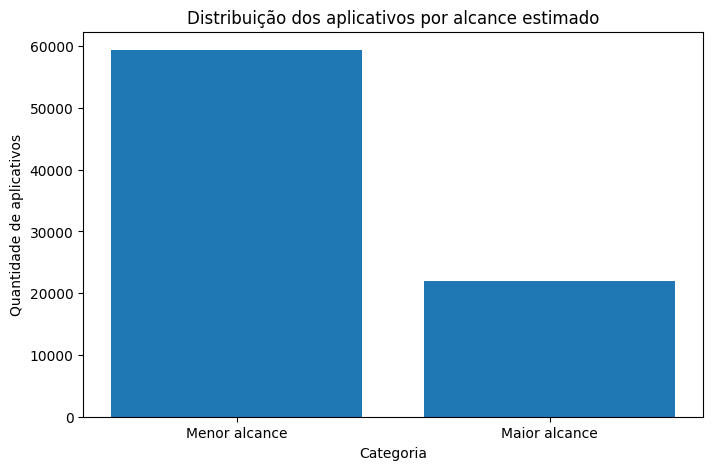

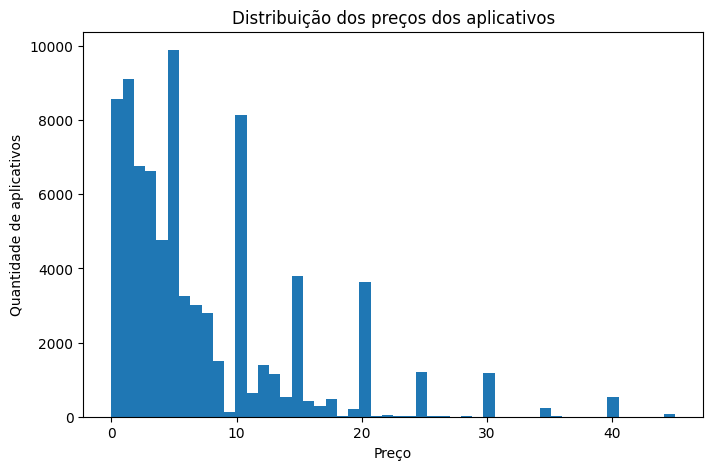

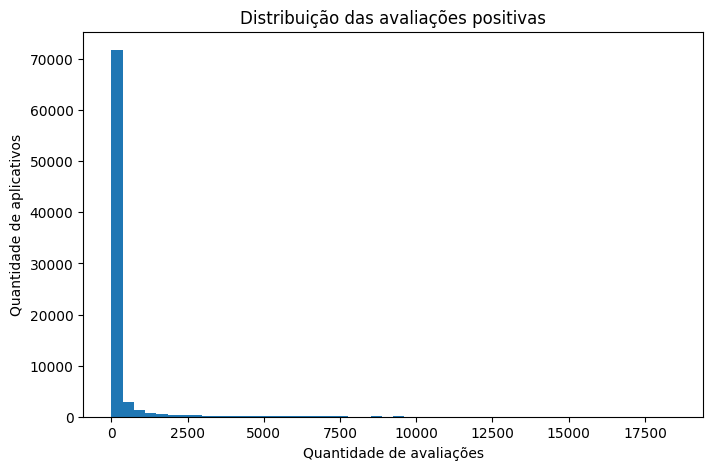

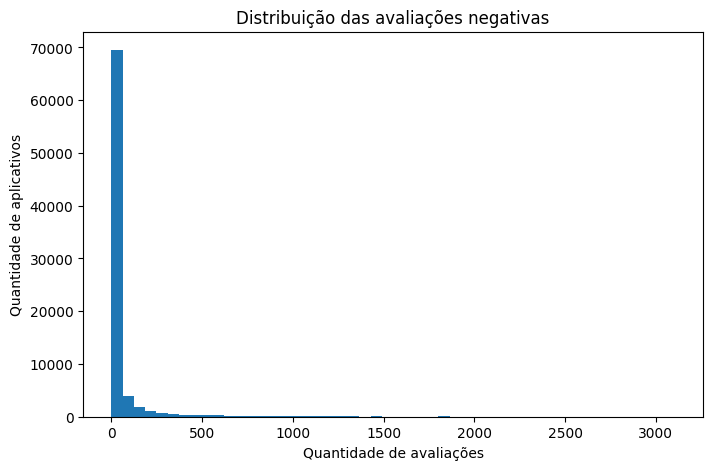

In [63]:


import matplotlib.pyplot as plt

#Registros de cada Categoria
contagem = dados['popularidade'].value_counts().sort_index()

plt.figure(figsize=(8, 5))

plt.bar(
    ['Menor alcance', 'Maior alcance'],
    contagem.values
)

plt.title('Distribuição dos aplicativos por alcance estimado')
plt.xlabel('Categoria')
plt.ylabel('Quantidade de aplicativos')

plt.show()

#Preços
precos = dados[dados['price'] <= dados['price'].quantile(0.99)]

plt.figure(figsize=(8, 5))
plt.hist(precos['price'], bins=50)

plt.title('Distribuição dos preços dos aplicativos')
plt.xlabel('Preço')
plt.ylabel('Quantidade de aplicativos')

plt.show()

#Avaliações positivas
positivas = dados[dados['positive'] <= dados['positive'].quantile(0.99)]

plt.figure(figsize=(8, 5))
plt.hist(positivas['positive'], bins=50)

plt.title('Distribuição das avaliações positivas')
plt.xlabel('Quantidade de avaliações')
plt.ylabel('Quantidade de aplicativos')

plt.show()

#Avaliações negativas
negativas = dados[dados['negative'] <= dados['negative'].quantile(0.99)]

plt.figure(figsize=(8, 5))
plt.hist(negativas['negative'], bins=50)

plt.title('Distribuição das avaliações negativas')
plt.xlabel('Quantidade de avaliações')
plt.ylabel('Quantidade de aplicativos')

plt.show()




**6 Preparação das variáveis para o KNN**

Para treinar o KNN é necessário separar as variáveis que serão utilizadas para realizar as previsões.

Elas são: Price, Positive e Negative

A variável popularidade será utilizada como alvo, representando a categoria que o modelo deverá prever.

Também será aplicada a transformação logarítmica nas quantidades de avaliações, utilizando log1p(). Essa transformação reduz a diferença entre valores muito pequenos e muito grandes, tornando a distribuição menos concentrada em valores extremos.

Em seguida, os dados serão divididos em conjuntos de treinamento e teste. O conjunto de treinamento será utilizado para ensinar o modelo, enquanto o conjunto de teste será reservado para avaliar seu desempenho em dados que não participaram do treinamento.

Por fim, será aplicada a padronização com StandardScaler, colocando as variáveis em escalas comparáveis. Essa etapa é especialmente importante para o KNN, pois seu funcionamento depende do cálculo de distâncias entre os registros.

In [42]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = dados[['price', 'positive', 'negative']].copy()
y = dados['popularidade'].copy()

X['positive'] = np.log1p(X['positive'])
X['negative'] = np.log1p(X['negative'])

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Padronização para o primeiro modelo
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

**7.1. Treinamento do primeiro modelo KNN**

Com os dados preparados, será realizado o treinamento inicial utilizando o algoritmo K-Nearest Neighbors (KNN).

O KNN é um algoritmo de aprendizado supervisionado que classifica um registro com base nas classes dos seus vizinhos mais próximos. Para isso, calcula a distância entre o novo registro e os exemplos presentes no conjunto de treinamento.

Neste primeiro teste, será utilizado `K=5`, considerando os cinco vizinhos mais próximos. A classe mais frequente entre esses vizinhos será escolhida como previsão.

Esse primeiro treinamento servirá como uma referência para avaliar o desempenho inicial do algoritmo antes de testar diferentes configurações.

In [43]:

from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

print("Treinamento concluído!")
print("Quantidade de previsões:", len(y_pred))

#Comparando provições com resultados reais
comparacao = pd.DataFrame({
    'Real': y_test.iloc[:10].values,
    'Previsto': y_pred[:10]
})

display(comparacao)


Treinamento concluído!
Quantidade de previsões: 16259


,Real,Previsto
0,0,0
1,0,0
2,1,1
3,0,0
4,0,0
5,1,1
6,0,0
7,0,0
8,0,0
9,0,0


**7.2 Avaliação do modelo inicial**

Após realizar as previsões, é necessário avaliar o desempenho do modelo e verificar se ele consegue identificar corretamente as duas categorias de alcance estimado.

Para isso, serão utilizadas métricas de classificação, como acurácia, precisão, recall e F1-score, e matriz de confusão.

Essas métricas ajudam a analisar não apenas a quantidade total de acertos, mas também o comportamento do modelo em cada categoria.

A análise é importante porque o dataset apresenta um desequilíbrio entre as classes, com uma quantidade maior de aplicativos classificados como de menor alcance.

Acurácia: 0.8554031613260348

Relatório de classificação:
               precision    recall  f1-score   support

Menor alcance       0.87      0.94      0.90     11876
Maior alcance       0.79      0.63      0.70      4383

     accuracy                           0.86     16259
    macro avg       0.83      0.78      0.80     16259
 weighted avg       0.85      0.86      0.85     16259



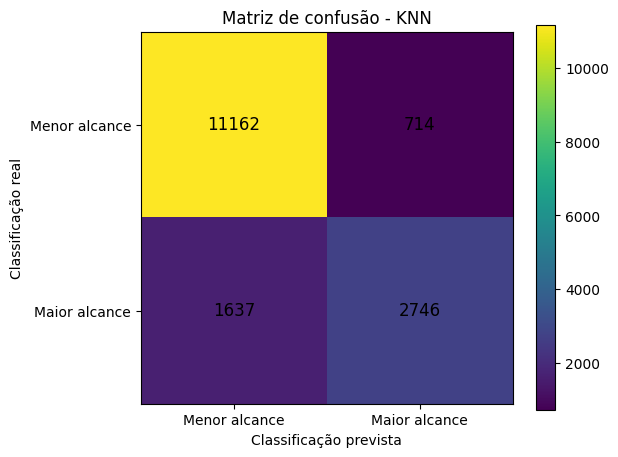

In [44]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

#Acurácia geral
print("Acurácia:", accuracy_score(y_test, y_pred))

#Relatório de classificação
print("\nRelatório de classificação:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['Menor alcance', 'Maior alcance']
))

#Matriz de confusão
matriz = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
plt.imshow(matriz)

plt.title('Matriz de confusão - KNN')
plt.xlabel('Classificação prevista')
plt.ylabel('Classificação real')

plt.xticks([0, 1], ['Menor alcance', 'Maior alcance'])
plt.yticks([0, 1], ['Menor alcance', 'Maior alcance'])

for i in range(2):
    for j in range(2):
        plt.text(j, i, matriz[i, j],
                 ha='center', va='center', fontsize=12)

plt.colorbar()
plt.show()


**8.1 Separação dos dados para validação**

Após a avaliação inicial, será realizada uma nova divisão do conjunto de treinamento, criando um conjunto de validação.

O objetivo é utilizar uma parte dos dados para comparar diferentes configurações do KNN sem utilizar o conjunto de teste nessa escolha.

A validação permite experimentar diferentes valores de K e estratégias de votação, identificando qual configuração apresenta melhor desempenho para reconhecer aplicativos de maior alcance.


In [45]:
X_train_val_raw, X_valid_raw, y_train_val, y_valid = train_test_split(
    X_train_raw, y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

#Padronização dos dados de treinamento da validação
scaler_valid = StandardScaler()

X_train_val = scaler_valid.fit_transform(X_train_val_raw)
X_valid = scaler_valid.transform(X_valid_raw)

print("Treinamento da validação:", X_train_val.shape[0])
print("Validação:", X_valid.shape[0])

Treinamento da validação: 52026
Validação: 13007


**8.2. Comparação de diferentes configurações do KNN**

Nesta etapa, serão testadas diferentes configurações do algoritmo KNN para identificar qual apresenta o melhor desempenho na classificação.

Serão comparados os valores de K iguais a 3, 5, 7, 9 e 11, além de duas estratégias de votação: uniform e distance.

Uniform atribui o mesmo peso a todos os vizinhos considerados. Distance dá maior influência aos vizinhos que estão mais próximos do registro analisado.

Para comparar os resultados, serão utilizadas a acurácia e o F1-score da categoria de maior alcance.

O F1-score dessa categoria recebe atenção especial porque o objetivo não é apenas acertar os aplicativos de menor alcance, mas também identificar aqueles que apresentam maior alcance estimado.

Ao final, as configurações serão organizadas de acordo com seu desempenho, permitindo selecionar a mais adequada para a avaliação final.

In [46]:
from sklearn.metrics import accuracy_score, f1_score

valores_k = [3, 5, 7, 9, 11]

#Tipos ponderação
pesos = ['uniform', 'distance']

resultados = []

#Test de configurações
for k in valores_k:
    for peso in pesos:

        modelo = KNeighborsClassifier(
            n_neighbors=k,
            weights=peso
        )

        modelo.fit(X_train_val, y_train_val)

        previsoes = modelo.predict(X_valid)

        resultados.append({
            'K': k,
            'Pesos': peso,
            'Acurácia': accuracy_score(y_valid, previsoes),
            'F1 - Maior alcance': f1_score(y_valid, previsoes, pos_label=1)
        })

#Resultados
resultado_knn = pd.DataFrame(resultados)

display(resultado_knn.sort_values(
    by='F1 - Maior alcance',
    ascending=False
))

,K,Pesos,Acurácia,F1 - Maior alcance
8,11,uniform,0.867072,0.720181
6,9,uniform,0.865995,0.718735
4,7,uniform,0.864150,0.716418
9,11,distance,0.857615,0.707425
7,9,distance,0.856693,0.705994
5,7,distance,0.854463,0.702592
2,5,uniform,0.855924,0.701877
3,5,distance,0.848389,0.692452
0,3,uniform,0.845314,0.686897
1,3,distance,0.840317,0.679722


**8.3 Treinamento do modelo final**

Após comparar as diferentes configurações, será selecionada aquela que apresentou o melhor resultado durante a validação.

O modelo final será treinado utilizando todo o conjunto de treinamento original, aproveitando também os registros que anteriormente foram separados para validação.

Antes do treinamento, será realizada uma nova padronização. Dessa vez, o `StandardScaler` será ajustado utilizando todo o conjunto de treinamento original, e seus parâmetros serão aplicados ao conjunto de teste.

Por fim, o modelo realizará previsões sobre os registros de teste, permitindo avaliar seu desempenho em dados que não participaram do treinamento.

In [64]:
#Padronização final
scaler_final = StandardScaler()

X_train_final = scaler_final.fit_transform(X_train_raw)
X_test_final = scaler_final.transform(X_test_raw)

knn_final = KNeighborsClassifier(
    n_neighbors=11,
    weights='uniform'
)

knn_final.fit(X_train_final, y_train)

y_pred_final = knn_final.predict(X_test_final)

print("Acurácia:", accuracy_score(y_test, y_pred_final))
print("\nRelatório:")
print(classification_report(
    y_test,
    y_pred_final,
    target_names=['Menor alcance', 'Maior alcance']
))

Acurácia: 0.8659204133095516

Relatório:
               precision    recall  f1-score   support

Menor alcance       0.88      0.95      0.91     11876
Maior alcance       0.83      0.63      0.72      4383

     accuracy                           0.87     16259
    macro avg       0.85      0.79      0.82     16259
 weighted avg       0.86      0.87      0.86     16259



O modelo final alcançou uma acurácia de aproximadamente 86,59% no conjunto de teste.

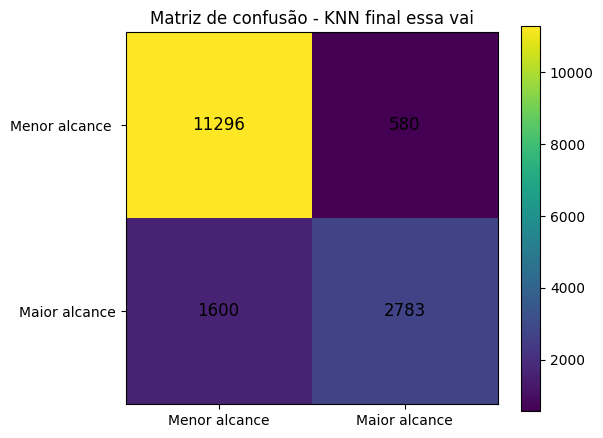

In [73]:

matriz = confusion_matrix(y_test, y_pred_final)

plt.figure(figsize=(6, 5))
plt.imshow(matriz)

plt.title('Matriz de confusão - KNN final essa vai')


plt.xticks([0, 1], ['Menor alcance', 'Maior alcance'])
plt.yticks([0, 1], ['Menor alcance ', 'Maior alcance'])

for i in range(2):
    for j in range(2):
        plt.text(j, i, matriz[i, j],
                 ha='center', va='center', fontsize=12)

plt.colorbar()
plt.show()

Web Scraping

Como um extra do projeto realizada uma pequena coleta de amostras do dataset original para utilizar no processo de Web Scraping.

São utilizadas `appid` e `name`, que identificam cada aplicativo. Em seguida, são removidos registros que possuem valores ausentes nessas colunas e são selecionados aleatoriamente cinco aplicativos.

A amostra ajuda a reduzir a quantidade de requisições necessárias e permite demonstrar o funcionamento do processo de extração sem precisar consultar todos os registros do dataset.

random_state garante que a seleção aleatória possa ser reproduzida em outras execuções.


In [49]:
import requests
from bs4 import BeautifulSoup

amostra = df[['appid', 'name']].dropna().sample(
    n=5,
    random_state=45
)

display(amostra)

,appid,name
56567,2342770,HinamiBay
50812,2668710,Puzzle Cube
21701,1164570,Phucker in the Rome
22024,549770,Paranormal Teens
17812,3070240,Derpy's Fun House


**9.2. Preparação dos endereços dos aplicativos**

Após selecionar a amostra inicial, são escolhidos três aplicativos para realizar o Web Scraping.

A seleção é feita utilizando `iloc`, que permite acessar registros pelas suas posições dentro do DataFrame. Em seguida, é criada uma nova coluna chamada `url`, contendo o endereço da página de cada aplicativo na loja Steam.

Para construir os endereços automaticamente, é utilizado o AppID de cada registro, pois esse identificador faz parte da estrutura das URLs da plataforma.

Dessa forma, cada aplicativo passa a ter seu próprio endereço, que será utilizado na etapa de requisições HTTP.

In [50]:
# Selecionando três aplicativos da amostra
jogos_scraping = amostra.iloc[[1, 3, 4]].copy()

# Criando os endereços das páginas da Steam
jogos_scraping['url'] = jogos_scraping['appid'].apply(
    lambda appid: f'https://store.steampowered.com/app/{appid}/'
)

display(jogos_scraping)

,appid,name,url
50812,2668710,Puzzle Cube,https://store.steampowered.com/app/2668710/
22024,549770,Paranormal Teens,https://store.steampowered.com/app/549770/
17812,3070240,Derpy's Fun House,https://store.steampowered.com/app/3070240/


**9.3. Acesso às páginas da Steam**

Com os endereços preparados, será realizada uma requisição HTTP para cada página selecionada.

A lib Requests acessa os endereços e obtem o conteúdo HTML retornado pelo servidor da Steam.

As respostas são armazenadas em um dicionário chamado paginas, utilizando o AppID como identificador. Isso permite recuperar posteriormente o HTML correspondente a cada aplicativo.

Também são exibidos o nome do aplicativo, o código de status HTTP e o tamanho do conteúdo recebido. Por fim, é utilizado um intervalo de dois segundos entre as requisições para evitar o envio de várias solicitações em sequência muito rápida.

In [51]:
import time

# Identificação da requisição
headers = {
    'User-Agent': 'Mozilla/5.0'
}

# Armazenar o conteúdo das páginas
paginas = {}

for _, jogo in jogos_scraping.iterrows():

    resposta = requests.get(
        jogo['url'],
        headers=headers,
        timeout=20
    )

    paginas[jogo['appid']] = resposta.text

    print(f"Jogo: {jogo['name']}")
    print(f"Status HTTP: {resposta.status_code}")
    print(f"Tamanho do HTML: {len(resposta.text)} caracteres")
    print("-" * 40)

    time.sleep(2)

Jogo: Puzzle Cube
Status HTTP: 200
Tamanho do HTML: 99034 caracteres
----------------------------------------
Jogo: Paranormal Teens
Status HTTP: 200
Tamanho do HTML: 91947 caracteres
----------------------------------------
Jogo: Derpy's Fun House
Status HTTP: 200
Tamanho do HTML: 93768 caracteres
----------------------------------------


**9.4. Extração das informações das páginas**

Após obter o HTML das páginas, será utilizada a biblioteca BeautifulSoup para interpretar sua estrutura e localizar as informações desejadas.

Para cada aplicativo, o conteúdo HTML é transformado em um objeto que permite pesquisar elementos por meio de seletores CSS.

As informações extraídas incluem nome, data de lançamento, gêneros, desenvolvedoras e publicadoras.

Os resultados são organizados em uma lista de dicionários e, posteriormente, convertidos em um DataFrame do Pandas.

Essa etapa transforma o conteúdo HTML, que originalmente é estruturado para exibição em páginas web, em informações tabulares que podem ser analisadas e comparadas com o dataset original.

In [52]:
# Lista para armazenar os resultados
resultados_scraping = []

for _, jogo in jogos_scraping.iterrows():

    # Interpretando o HTML
    soup = BeautifulSoup(
        paginas[jogo['appid']],
        'html.parser'
    )

    # Extraindo as informações
    nome = soup.select_one('.apphub_AppName')
    data = soup.select_one('.date')

    generos = soup.select(
        '#genresAndManufacturer a[href*="/genre/"]'
    )

    desenvolvedoras = soup.select(
        '#developers_list a'
    )

    publicadoras = soup.select(
        '#publishers_list a'
    )

    resultados_scraping.append({
        'AppID': jogo['appid'],
        'Nome': nome.get_text(strip=True) if nome else None,
        'Data de lançamento': data.get_text(strip=True) if data else None,
        'Gêneros': ', '.join(g.get_text(strip=True) for g in generos),
        'Desenvolvedora': ', '.join(d.get_text(strip=True) for d in desenvolvedoras),
        'Publicadora': ', '.join(p.get_text(strip=True) for p in publicadoras)
    })

# Transformando os resultados em DataFrame
df_scraping = pd.DataFrame(resultados_scraping)

display(df_scraping)

,AppID,Nome,Data de lançamento,Gêneros,Desenvolvedora,Publicadora
0,2668710,Puzzle Cube,"Nov 17, 2023","Casual, Strategy",BeachBlock Games,
1,549770,Paranormal Teens,"Dec 28, 2016","Indie, Simulation","Visual Wordplay, Godline",
2,3070240,Derpy's Fun House,"Aug 7, 2024","Casual, Indie, Free To Play",Raztudio,


In [53]:
# Salvando os dados coletados
df_scraping.to_csv(
    'steam_scraping.csv',
    index=False,
    encoding='utf-8-sig'
)

print("Dados salvos")

Dados exportados com sucesso!


**9.6 Comparação dos dados coletados com o dataset original**

Nesta etapa, as informações obtidas pelo Web Scraping serão comparadas com os registros presentes no dataset original.

O objetivo é reunir informações de diferentes fontes em uma única tabela, permitindo observar os dados de alcance estimado junto às informações complementares extraídas das páginas da Steam.

Para realizar essa comparação, será utilizado o AppID como identificador dos aplicativos. Essa escolha é mais confiável do que utilizar apenas o nome, pois diferentes registros podem apresentar nomes iguais.

A operação de junção será realizada com `merge()`, utilizando o tipo de combinação `inner`, que mantém somente os registros encontrados nas duas fontes.

In [61]:
# Comparando os dados coletados com o dataset original
comparacao = df[
    ['appid', 'name', 'estimated_owners']
].merge(
    df_scraping,
    left_on='appid',
    right_on='AppID',
    how='inner'
)

display(
    comparacao[
        ['appid', 'name', 'estimated_owners',
         'Data de lançamento', 'Gêneros',
         'Desenvolvedora', 'Publicadora']
    ]
)


,appid,name,estimated_owners,Data de lançamento,Gêneros,Desenvolvedora,Publicadora
0,3070240,Derpy's Fun House,0 - 0,"Aug 7, 2024","Casual, Indie, Free To Play",Raztudio,
1,549770,Paranormal Teens,0 - 20000,"Dec 28, 2016","Indie, Simulation","Visual Wordplay, Godline",
2,2668710,Puzzle Cube,0 - 0,"Nov 17, 2023","Casual, Strategy",BeachBlock Games,


In [60]:
# Verificando os três aplicativos no dataset original
display(
    df[df['appid'].isin(jogos_scraping['appid'])][
        ['appid', 'name', 'estimated_owners']
    ]
)

,appid,name,estimated_owners
17812,3070240,Derpy's Fun House,0 - 0
22024,549770,Paranormal Teens,0 - 20000
50812,2668710,Puzzle Cube,0 - 0
